# Analyse Oocytor results for mouse movies - comparison Ana dataset and Adrien dataset, same scale

Plot the features values measured with Oocytor. 
Raw datas files are in the results `resultsScale_*` folder. 

In [1]:
rm(list=ls())

library(gridExtra)
library(ggsignif)

## Graphics settings

Define the default plotting option (graph backgrounds, margins, text size...). 
Can be modified here to change all the graphs settings 

In [2]:
library(ggplot2)

theme_plots <- function (base_size = 11, base_family = "") 
{
    theme_classic() %+replace% 
    theme(
	  #plot.background = element_blank(),
      panel.grid.major  = element_blank(),
      panel.grid.minor  = element_blank(),
      panel.background = element_blank(),
      panel.border = element_blank(),
	  panel.spacing = unit(0, "lines"),
      axis.line = element_line(color = "black", size=1.4),
      axis.ticks = element_line(color = "black", size=1.7),
      axis.text = element_text(color = "black"),
	  axis.text.x=element_text(angle=0, size=32, vjust=0.5),
	  axis.text.y=element_text(angle=0, size=32, vjust=0.5, margin=ggplot2::margin(0,0,0,0)),
	  axis.title.x = element_text(color="black", size=36, vjust=-0.35, margin=ggplot2::margin(5,0,0,0)),
	  axis.title.y = element_text(color="black", size=36, vjust=0.35, angle=90, margin=ggplot2::margin(0,10,0,0)),
	  legend.background = element_rect(fill = "white", color="white"),
	  legend.text = element_text(color="gray20", size=15),
	  legend.key = element_rect(fill = "white", colour = "white"),
	  legend.position="none",
	  plot.margin = grid::unit(c(0.3,0.3,0.3,0), "cm")
      )
}

In [3]:
## Display color for Control and KO oocytes, you can modify it here for all graphs

controlColor = rgb(20/255, 130/255, 90/255,1)
KOColor = rgb(255/255,30/255,0/255,1)
MivColor = rgb(20/255,90/255,130/255,1)
MivBisColor = rgb(30/255,70/255,180/255,1)
MixColor = rgb(20/255,50/255,170/255,1)


myCol = c(controlColor, KOColor, MixColor, MivBisColor)

## Load and prepare data

In [4]:
## parameters

resf = "resultsMouseScale_2511"  ## folder where the results and the raw data are
movo = "as"                ## name of the files

## load data
rdatas = read.table(paste(resf,"/", movo, "_rawDatas.txt",sep=""), header=T, sep="\t")
rdatas$OoDiameter=rdatas$OoPerimeter/pi
meandatas = read.table(paste(resf,"/", movo, "_meanDatas.txt",sep=""), header=T, sep="\t")
whos = read.table(paste(resf,"/", movo, "_whos.txt",sep=""), header=T, sep="\t")


## Number of oocytes of each type
print(paste("0- Control, N0=", sum(meandatas$Type==1), sep=""))
print(paste("1- KO, N1=", sum(meandatas$Type==2), sep=""))
print(paste("2- MIV, N2=", sum(meandatas$Type==3), sep=""))
print(paste("3- MIVBis, N3=", sum(meandatas$Type==4), sep=""))
print(paste("4- MIVTer, N4=", sum(meandatas$Type==5), sep=""))

[1] "0- Control, N0=77"
[1] "1- KO, N1=78"
[1] "2- MIV, N2=59"
[1] "3- MIVBis, N3=152"
[1] "4- MIVTer, N4=223"


In [5]:
## keep only dividing in plane for MIV dataset
mivset = read.table( "../dataComp/Miv/liste.csv", header=T, sep=",")
keep = (mivset$DividePlan == 1) | (mivset$DividePlan == 3)
#print(mivset$FileName[keep])
whomiv = whos[whos$Folder == "Miv",]
keepNum = whomiv$Num[ paste(whomiv$Movie, ".tif", sep="") %in% mivset$FileName[keep] ]
notmiv = whomiv$Num[! whomiv$Num %in% keepNum]
rdatas = rdatas[!rdatas$Num %in% notmiv,]
meandatas = meandatas[!meandatas$Num %in% notmiv,]

## keep only dividing in plane for MIVbis dataset
mivbisset = read.table( "../dataComp/Mivbis/liste.csv", header=T, sep=",")
keepbis = (mivbisset$DividePlan == 1) | (mivbisset$DividePlan == 3)
#print(mivset$FileName[keep])
whomivbis = whos[whos$Folder == "Mivbis",]
keepNumbis = whomivbis$Num[ paste(whomivbis$Movie, ".tif", sep="") %in% mivbisset$FileName[keepbis] ]
notmivbis = whomivbis$Num[! whomivbis$Num %in% keepNumbis]
rdatas = rdatas[!rdatas$Num %in% notmivbis,]
meandatas = meandatas[!meandatas$Num %in% notmivbis,]

## keep only dividing in plane for MIVbis dataset
mivterset = read.table( "../dataComp/Mivter/liste.csv", header=T, sep=",")
keepter = (mivterset$DividePlan == 1) | (mivterset$DividePlan == 3)
#print(mivset$FileName[keep])
whomivter = whos[whos$Folder == "Mivter",]
keepNumter = whomivter$Num[ paste(whomivter$Movie, ".tif", sep="") %in% mivterset$FileName[keepter] ]
notmivter = whomivter$Num[! whomivter$Num %in% keepNumter]
rdatas = rdatas[!rdatas$Num %in% notmivter,]
meandatas = meandatas[!meandatas$Num %in% notmivter,]

rdatas$Type[rdatas$Type==4] = 3
rdatas$Type[rdatas$Type==5] = 3

meandatas$Type[meandatas$Type==4] = 3
meandatas$Type[meandatas$Type==5] = 3


## Number of oocytes of each type after removal of oocytes not dividing in plane
print(paste("0- Control, N0=", sum(meandatas$Type==1), sep=""))
print(paste("1- KO, N1=", sum(meandatas$Type==2), sep=""))
print(paste("2- MIV, N2=", sum(meandatas$Type==3), sep=""))
print(paste("3- MIVBis, N3=", sum(meandatas$Type==4), sep=""))

[1] "0- Control, N0=77"
[1] "1- KO, N1=78"
[1] "2- MIV, N2=130"
[1] "3- MIVBis, N3=0"


In [6]:
## align time relatively to Polar Body expulsion (last point of each movie)

alignTime = function( data )
{
    data$TimeToGP = data$Time
    for (num in unique(data$Num))
    {
        keep = data$Num == num
        lasttime = max(data$Time[keep])
        data$TimeToGP[keep] = data$Time[keep]-lasttime
    }
    return (data)
}

rdatas = alignTime(rdatas)

In [7]:
noo = length(unique(rdatas$Num))
print(noo)
mint = 0
for (t in unique(rdatas$TimeToGP))
{
    noot = length(unique(rdatas$Num[rdatas$TimeToGP==t]))
    if (noot == noo)
    {
            if (mint > t){mint=t}
    }
}
print(mint)

[1] 285
[1] -114


List all the available features

In [8]:
names(meandatas)

[1] "Time"                           "OoArea"                        
 [3] "OoMajorAxisLength"              "OoMinorAxisLength"             
 [5] "OoEllAspectRatio"               "OoFeretDiam"                   
 [7] "OoPerimeter"                    "OoCircularity"                 
 [9] "OoRoundness"                    "OoConvexity"                   
[11] "OoCurvatureMean"                "OoCurvatureStd"                
[13] "OoCurvatureCoefVar"             "OoCurvatureMax"                
[15] "OoCurvatureMin"                 "OoCurvatureFlatProp"           
[17] "OoCurvatureBendingEnergy"       "OoCurvatureNormalisedMean"     
[19] "OoCurvatureNormalisedMax"       "OoCurvatureNormalisedMin"      
[21] "OoCurvatureNormalisedStd"       "OoKurtosis"                    
[23] "OoNormMean"                     "OoNormStd"                     
[25] "OoNormCoefVar"                  "Type"                          
[27] "Num"                            "PerivArea"                     
[29] "PerivOoAreaRatio"               "PerivThicknessMean"            
[31] "PerivThicknessMin"              "PerivThicknessMax"             
[33] "PerivThicknessStd"              "PerivThicknessCoefVar"         
[35] "OoGLCMAngular2Moment"           "OoGLCMEntropy"                 
[37] "OoGLCMInverseDiffMoment"        "OoGLCMClusterTendency"         
[39] "OoGLCMClusterShade"             "OoGLCMCorrelation"             
[41] "OoGLCMContrast"                 "OoGLCMHomogeneity"             
[43] "OoGLCMVariance"                 "OoMoranIndexK5"                
[45] "OoMoranIndexK20"                "ZPGLCMAngular2Moment"          
[47] "ZPGLCMEntropy"                  "ZPGLCMInverseDiffMoment"       
[49] "ZPGLCMClusterTendency"          "ZPGLCMClusterShade"            
[51] "ZPGLCMCorrelation"              "ZPGLCMContrast"                
[53] "ZPGLCMHomogeneity"              "ZPGLCMVariance"                
[55] "OoFluctuationMean"              "OoFluctuationStd"              
[57] "OoFluctuationPropMoving"        "OoFluctuationPropGrowing"      
[59] "OoFluctuationSpatialMode"       "OoFluctuationSpatialPower"     
[61] "OoFluctuationSpatialCorrLength" "OoFluctuationFromLocalMean"    
[63] "OoFluctuationFromLocalStd"      "OoRadiusMean"                  
[65] "OoRadiusStd"                    "OoRadiusDiffMean"              
[67] "OoRadiusDiffStd"                "OoPIVMean"                     
[69] "OoPIVStd"                       "OoPIVCoefVar"                  
[71] "OoPIVMeanCenter"                "OoPIVMeanEdge"                 
[73] "OoPIVAngleCenter"               "OoPIVAngleEdge"                
[75] "OoPIVAverageDirection"          "OoPIVStrengthDirection"        
[77] "OoPIVAverageDirectionCenter"    "OoPIVAverageDirectionEdge"     
[79] "OoPIVStrengthDirectionCenter"   "OoPIVStrengthDirectionEdge"    
[81] "OoParticleDistanceMean"         "OoParticleDistanceStd"         
[83] "OoParticleDistanceCoefVar"      "OoParticleNumber"              
[85] "OoParticleAverageSize"

### Add special features

In [9]:
tnormmin = -20
tnormmax = 0
normdata = rdatas[rdatas$TimeToGP>=tnormmin&rdatas$TimeToGP<=tnormmax,]
GPdatas = aggregate( normdata, list(normdata$Num), mean )

rdatas$OoNormedAR = rep(0, length(rdatas$OoEllAspectRatio))
rdatas$OoNormedPIVDirCenter = rep(0, length(rdatas$OoPIVStrengthDirectionCenter))
rdatas$OoNormedPIVAngleEdge = rep(0, length(rdatas$OoPIVAngleEdge))
rdatas$OoNormedFluctuationSpatialPower = rep(0, length(rdatas$OoFluctuationSpatialPower))
rdatas$OoNormedFluctuationLocalMean = rep(0, length(rdatas$OoFluctuationFromLocalMean))

for (num in unique(rdatas$Num))
{
    rdatas$OoNormedAR[rdatas$Num==num] = rdatas$OoEllAspectRatio[rdatas$Num==num]/GPdatas$OoEllAspectRatio[GPdatas$Num==num]
    rdatas$OoNormedPIVDirCenter[rdatas$Num==num] = rdatas$OoPIVStrengthDirectionCenter[rdatas$Num==num]/GPdatas$OoPIVStrengthDirectionCenter[GPdatas$Num==num]
    rdatas$OoNormedPIVAngleEdge[rdatas$Num==num] = rdatas$OoPIVAngleEdge[rdatas$Num==num]/GPdatas$OoPIVAngleEdge[GPdatas$Num==num]
    rdatas$OoNormedFluctuationSpatialPower[rdatas$Num==num] = rdatas$OoFluctuationSpatialPower[rdatas$Num==num]/GPdatas$OoFluctuationSpatialPower[GPdatas$Num==num]
    rdatas$OoNormedFluctuationLocalMean[rdatas$Num==num] = rdatas$OoFluctuationFromLocalMean[rdatas$Num==num]/GPdatas$OoFluctuationFromLocalMean[GPdatas$Num==num]
}

## Plot features temporal evolution

In [10]:
## Plot feature "feat" evolution in time for oocytes grouped by "Type" and colored with "colour_by"

plotTimeToGPFeature = function(data, feat, tmin, tmax, colour_by)
{
	indfeat = which(names(data)==feat)
	allfeat = data[,indfeat]
	data = data[data$TimeToGP>=tmin&data$TimeToGP<=tmax,]
	data$Type= factor(data$Type, levels=c(1,2,3,4))

	p = ggplot(data, aes(x=TimeToGP, y=get(feat), group=Num, colour=get(colour_by)) )	
	p = p + geom_smooth(data=data, aes(x=TimeToGP, y=get(feat), group=get(colour_by), colour=get(colour_by), linetype=get(colour_by)), method="loess", span=0.5, size=1.8)
	p = p + scale_colour_manual(values=myCol )
	p = p + scale_linetype_manual(values = c("solid", "solid", "solid", "solid"))
	p = p +theme(legend.position="none") 
	p = p + geom_vline(xintercept=0, linetype="dashed", color="gray60", size=0.5)  
	p = p + ylab(feat)
	p = p + theme_plots()
	p = p + xlab("Time to GP (min)")
	return(p)
}

### Plot one feature evolution in time

Choose the feature to plot in the `feature` parameter (the list of possible features is displayed above).

To change the y-axis limits, put `limit_y` to `TRUE` and choose the `miny` and `maxy` values.

To change the x-axis limits, change the values of `maxtime` and `mintime`

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”
Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.”
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


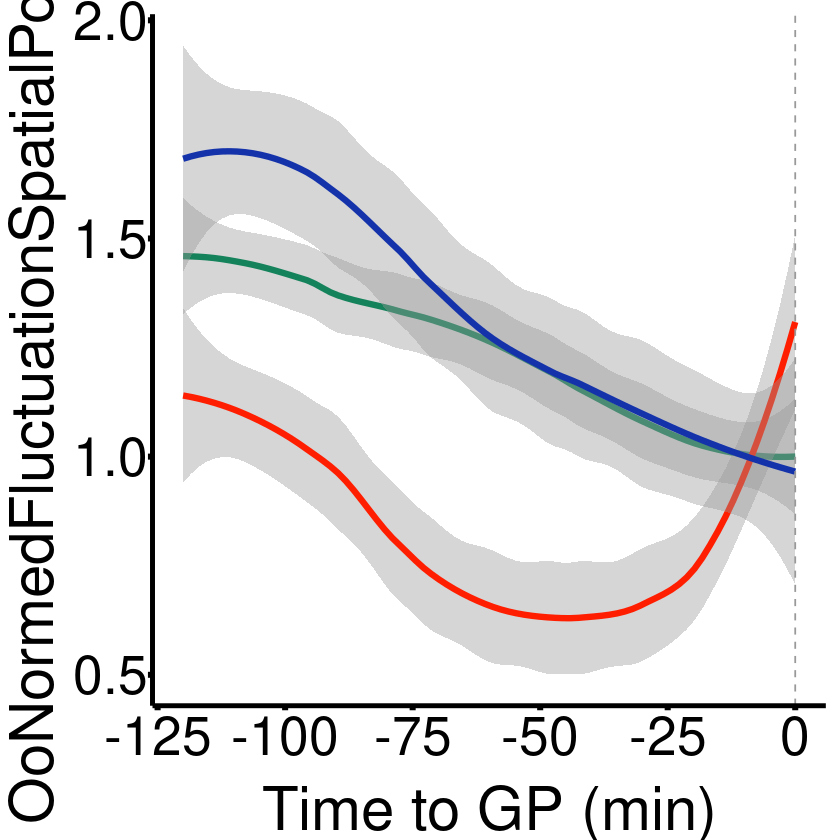

In [11]:
## Feature to plot
feature = "OoFeretDiam"
feature = "OoPIVStrengthDirectionCenter"
feature = "OoNormedPIVDirCenter"
feature = "OoPIVAngleEdge"
#feature = "OoParticleDistanceMean"
feature = "OoFluctuationFromLocalMean"
feature = "OoEllAspectRatio"
feature = "OoFluctuationSpatialPower"
feature = "OoNormedAR"
feature = "OoNormedPIVAngleEdge"
#feature = "OoNormedFluctuationLocalMean"
feature = "OoNormedPIVDirCenter"
feature = "OoNormedFluctuationSpatialPower"

#rdatas = rdatas[rdatas$Type<=2,]

## Plot from mintime to maxtime, can change it
maxtime = max(rdatas$TimeToGP)
mintime = -120

## Limit the y coordinates
limit_y = FALSE ## if FALSE, default limit to the value range
miny = 1
maxy = 1.1

## Feature to use for coloring the plots
color_feature = "Type"

## Do the plotting
p = plotTimeToGPFeature(rdatas, feature, mintime, maxtime, color_feature)
if ( limit_y ) {p = p + ylim(miny,maxy)}
print(p)

ggsave(paste(resf, "/", feature,"_time.svg",sep=""), plot=p, width=15, height=10)

In [12]:
## Save the plots in the results folder
ggsave(paste(resf, "/", feature,"_time.svg",sep=""), plot=p, width=15, height=10)

`geom_smooth()` using formula = 'y ~ x'


## Plot features comparison between Control and KO

In [13]:
## Plot Feature according to Manual KO or not

boxplotFeature = function(data, feat, time, tmin, tmax)
{
    data = data[time>=tmin&time<=tmax,]
	mcdata = aggregate( data, list(data$Num), mean )
	ct = (tmax+tmin)/2
	mcdata$TimeToGP = ct
	mcdata = as.data.frame(mcdata)
	mcdata$Type = as.factor(mcdata$Type)
	
    p = ggplot(mcdata, aes(x=Type, y=get(feat), fill=Type, color=Type) )	
	p = p + geom_violin( position=position_dodge(width = 0.7), alpha=0.3,size=1)
	p = p + geom_point(pch = 21, position = position_jitterdodge())
	p = p + labs(y=feat, title=paste("At ",ct," min", sep=""))
	p = p + scale_colour_manual(values=myCol )
	p = p + scale_fill_manual(values=myCol )
	p = p + theme_plots() 

	indfeat = which(names(mcdata)==feat)
	ymax = max(mcdata[,indfeat])	
    if (sum(mcdata$Type==1)>0)
	{
		ks = ks.test( mcdata[mcdata$Type==1, indfeat], mcdata[mcdata$Type==2, indfeat] )
		p = p + geom_signif( annotation=formatC(ks$p.value, digits=2), color=myCol[1], y_position=ymax*0.95, xmin=1, xmax=2 )
    }
    
    ymax = max(mcdata[,indfeat])
    ymin = min(mcdata[,indfeat])

    return (list(p, ymin, ymax))
}

### Plot the boxplot of one feature comparing KO to Control

Choose the feature to plot with the `feature` parameter

The features are averaged on the time window of size `2*dt`. To choose the time points to plot, change the `times` parameter.
The values plotted are averaged from `times-dt` to `times+dt` for each time point in times.

Mouse movies are every 2 min.

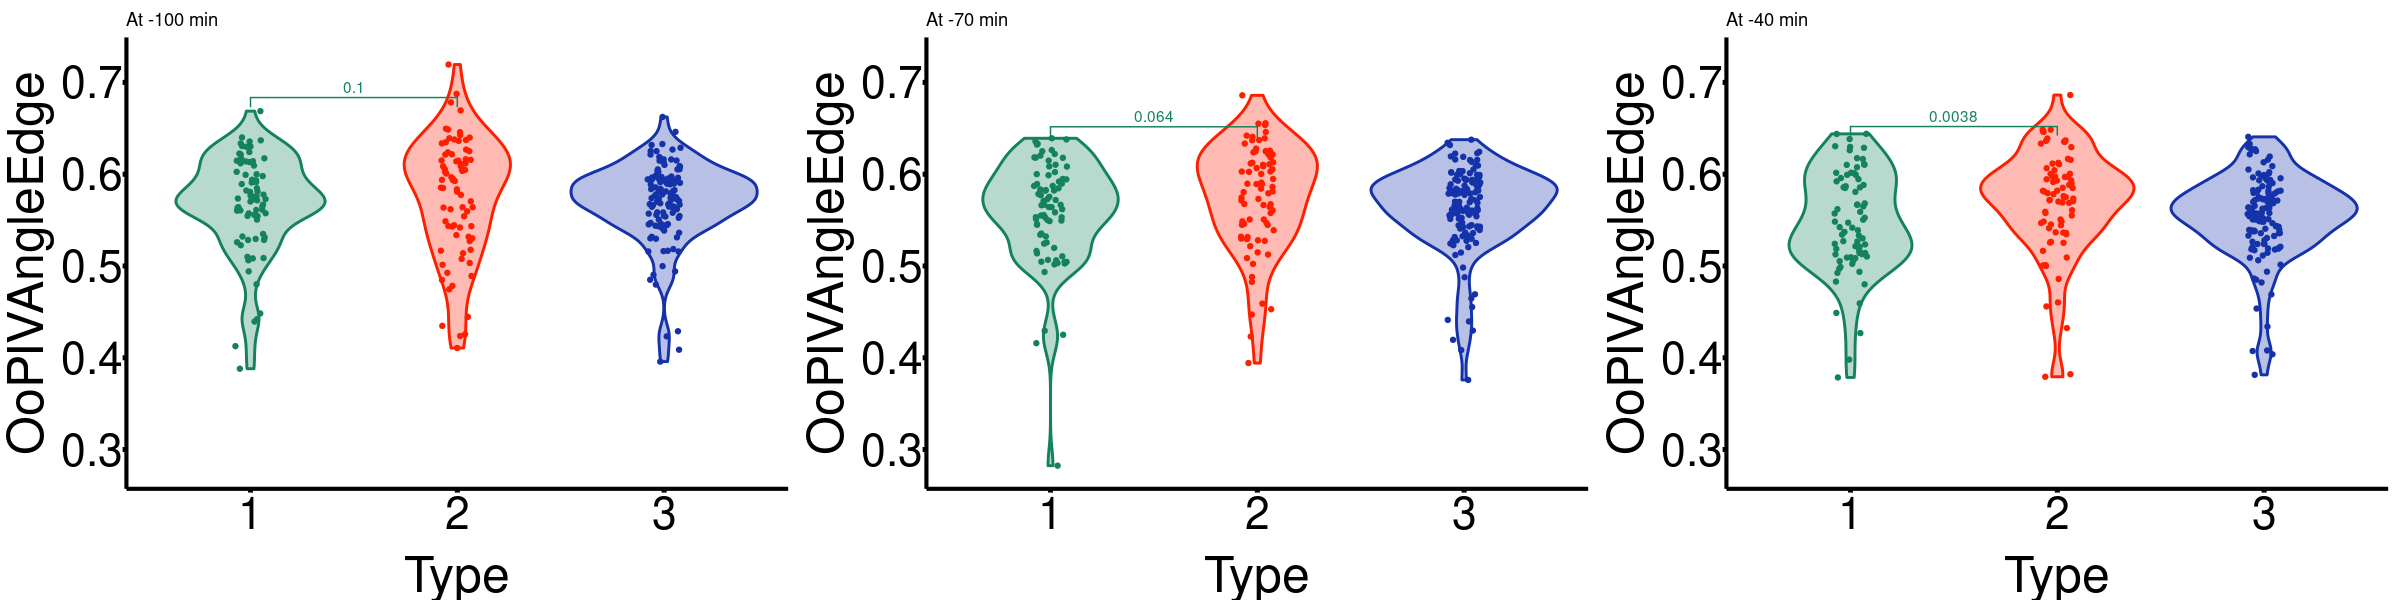

In [14]:
feature = "OoPIVStrengthDirection"   ## feature to plot
feature = "OoPIVStrengthDirectionCenter"
feature = "OoNormedPIVDirCenter"
feature = "OoPIVAngleEdge"
#feature = "OoParticleDistanceMean"
#feature = "OoFluctuationFromLocalMean"
#feature = "OoEllAspectRatio"
#feature = "OoFluctuationSpatialPower"
#feature = "OoNormedFluctuationSpatialPower"
#feature = "OoNormedAR"
#feature = "OoNormedPIVAngleEdge"
#feature = "OoNormedFluctuationLocalMean"
#feature = "OoNormedPIVDirCenter"
#feature="OoArea"
dt = 10                        ## half-time interval on which datas are averaged
times = c(-40, -70, -100)      ## times to plot (central time). Data are averaged from central_time-dt to central_time+dt

boxplots = list()
ymin = 10000
ymax = -10000
for (i in 1:3)
{
    resbp = boxplotFeature(rdatas, feature, rdatas$TimeToGP, times[i]-dt, times[i]+dt)
    boxplots[[i]] = resbp
    ymin = min(ymin, resbp[[2]])
    ymax = max(ymax, resbp[[3]])
}

for (i in 1:3)
{
    boxplots[[i]][[1]] = boxplots[[i]][[1]] + ylim(ymin*0.99, ymax*1.01)
}

options(repr.plot.width = 24, repr.plot.height = 6, repr.plot.res = 100)
p = grid.arrange(boxplots[[3]][[1]], boxplots[[2]][[1]], boxplots[[1]][[1]], ncol = 3, nrow = 1)

## Save the plots
ggsave(plot=p, paste(resf, "/", feature, "_boxplots.svg", sep=""), width=24, height=8)

In [15]:
## Save the plots
ggsave(plot=p, paste(resf, "/", feature, "_boxplots.svg", sep=""), width=24, height=8)

### Test comparaison feature value just before expulsion

In [16]:
## Compare Feature normalized by its value before expulsion 

boxplotFeatureNormalised = function(data, feat, time, tmin, tmax, tnormmin, tnormmax)
{
    dataGP = data[time>=tnormmin&time<=tnormmax,]
	mcdataGP = aggregate( dataGP, list(dataGP$Num), mean )
    
    data = data[time>=tmin&time<=tmax,]
	mcdata = aggregate( data, list(data$Num), mean )
    ct = (tmax+tmin)/2
	mcdata$TimeToGP = ct
	mcdata = as.data.frame(mcdata)
	mcdata$Type = as.factor(mcdata$Type)
	
    indfeat = which(names(mcdata)==feat)
    mcdata[,indfeat] = mcdata[,indfeat]/mcdataGP[,indfeat]
	
    p = ggplot(mcdata, aes(x=Type, y=get(feat), fill=Type, color=Type) )	
	p = p + geom_violin( position=position_dodge(width = 0.7), alpha=0.3,size=1)
	p = p + geom_point(pch = 21, position = position_jitterdodge())
	p = p + labs(y=feat, title=paste("At ",ct," min", sep=""))
	p = p + scale_colour_manual(values=myCol )
	p = p + scale_fill_manual(values=myCol )
	p = p + theme_plots() 

	ymax = max(mcdata[,indfeat])	
    if (sum(mcdata$Type==1)>0)
	{
		ks = ks.test( mcdata[mcdata$Type==1, indfeat], mcdata[mcdata$Type==2, indfeat] )
		p = p + geom_signif( annotation=formatC(ks$p.value, digits=2), color=myCol[1], y_position=ymax*0.95, xmin=1, xmax=2 )
    }
    
    ymax = max(mcdata[,indfeat])
    ymin = min(mcdata[,indfeat])

    return (list(p, ymin, ymax))
}

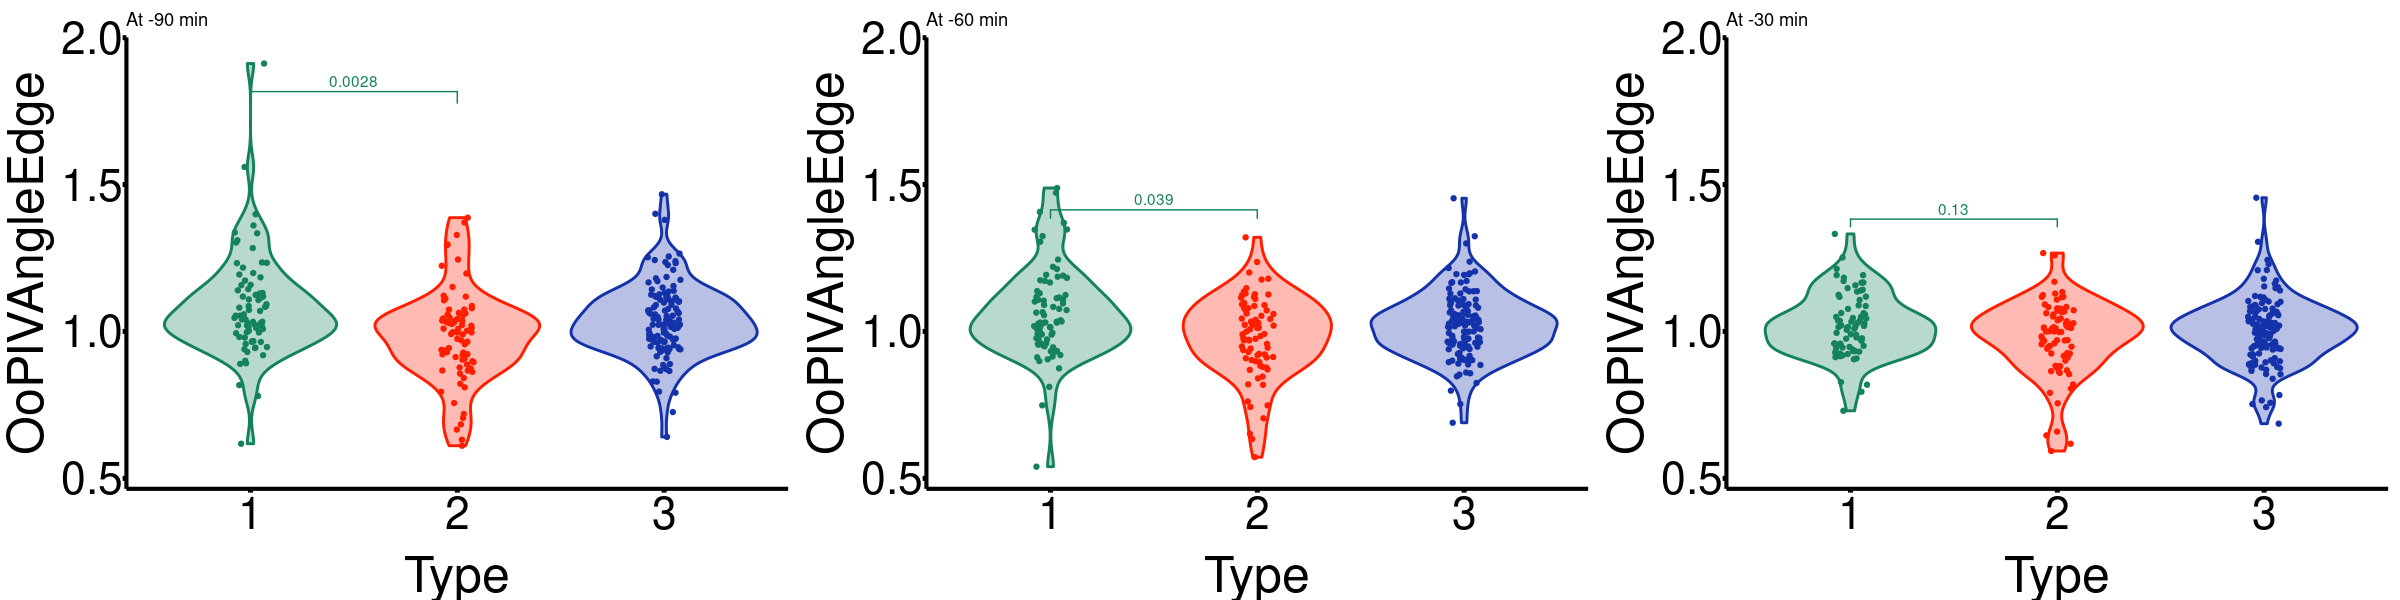

In [17]:
feature = "OoPIVAngleEdge"   ## feature to plot
dt = 10                     ## half-time interval on which datas are averaged
times = c(-30, -60, -90)      ## times to plot (central time). Data are averaged from central_time-dt to central_time+dt

boxplots = list()
ymin = 10000
ymax = -10000
for (i in 1:3)
{
    resbp = boxplotFeatureNormalised(rdatas, feature, rdatas$TimeToGP, times[i]-dt, times[i]+dt, -5, 0)
    boxplots[[i]] = resbp
    ymin = min(ymin, resbp[[2]])
    ymax = max(ymax, resbp[[3]])
}

for (i in 1:3)
{
    boxplots[[i]][[1]] = boxplots[[i]][[1]] + ylim(ymin*0.99, ymax*1.01)
}

options(repr.plot.width = 24, repr.plot.height = 6, repr.plot.res = 100)
p = grid.arrange(boxplots[[3]][[1]], boxplots[[2]][[1]], boxplots[[1]][[1]], ncol = 3, nrow = 1)

### Random forest

In [18]:
## do the random Forest only on Ana's data
rfdatas = rdatas[rdatas$Type<=2,]
meanfdatas = meandatas[meandatas$Type<=2,]

In [19]:
source("ooSubsetSelect.R")
source("ooscale.R")
source("ooAugment.R")
source("ooFunctions.R")

naug = 0
write = 1
plotFeatImp = 1
savePred = 0
nfold = 5

dt = 10
dot = seq(-150,-10,5) #c(-150,-140,-130,-120,-110,-100,-90,-80,-70,-60,-50,-40,-30,-20,-10)
#dot=-40

rfdatas$Time = rfdatas$TimeToGP

library(randomForest) 
print( paste("proba ", sum(meanfdatas$Type==1)/length(meanfdatas$Type), sep="") )

nums = meandatas$Num
scorenums = rep(-1, length(nums))

eachres = c()
eachgt = c()
allres = c()
allresboth = c()

for ( t in dot )
{
	print(paste("Time ", t, sep=""))
	tmin = t-dt
	tmax = t+dt

	# Select subset of uncorrelated features
	subdatas = projData(rfdatas, tmin, tmax)
	subset = subsetCluster( subdatas, 0.8)	

	#Randomly shuffle the data
	rnums = nums[sample(length(nums))]
	#Create equally size folds
	folds <- cut(seq(1,length(rnums)),breaks=nfold,labels=FALSE)
	#Perform 10 fold cross validation
	predictors = list()
	restest = c()

	for(i in 1:nfold) {
		#Separate data by fold using the which() function 
		testIndexes <- which(folds==i,arr.ind=TRUE)
		testnums = rnums[testIndexes]

		## Training
		trainData = rfdatas[ !rfdatas$Num%in%testnums,]
		## scale datas
		tdatas = projData(trainData, tmin, tmax)
		if (savePred){
		saveRDS(subset, file=paste(fold, "/predictors/predictorK", "_subset", "_bal", balanced, "_aug", naug, "_t", tmin, ".Rds", sep="") )
		}

		## subset selection
		tokeep = names(tdatas) %in% names(subset)
		subkeep = tdatas[,tokeep]
		types = tdatas$Type
		## RF
		wdatas = cbind(subkeep, types)
		names(wdatas)[length(names(wdatas))] = "Type"

		## SMOTE	
		if (naug>0) {
			for ( aug in 1:(naug) ) {
				auged = smote( wdatas[wdatas$Type==1,], 20 )
				dauged = data.frame(auged)
				colnames(dauged) = colnames(wdatas)
				rownames(dauged) = rep(length(wdatas[,1]), length(dauged[,1])) + 1:length(dauged[,1])
				wdatas = rbind( wdatas, dauged)
				
				auged = smote( wdatas[wdatas$Type==2,], 20 )
				dauged = data.frame(auged)
				colnames(dauged) = colnames(wdatas)
				rownames(dauged) = rep(length(wdatas[,1]), length(dauged[,1])) + 1:length(dauged[,1])
				wdatas = rbind( wdatas, dauged)
			}
		}	

		## Do RandomForest
		predictor = randomForest( as.factor(Type)~., data=wdatas, ntree=1000, na.action=na.roughfix )
		predictors[[i]] = predictor


		if (savePred){
		save(predictor, file=paste(fold, "/predictors/predictorK", "_bal", balanced, "_aug", naug, "_t", tmin, ".RData", sep="") )
		}

		#### Test
		testData = rfdatas[ rfdatas$Num%in%testnums,]
		## scale
		trfdatas = projData(testData, tmin, tmax)

		## subset
		gt = trfdatas$Type
		t0num = trfdatas$Num
		ckeep = names(trfdatas) %in% names(subset)
		trfdatas = trfdatas[,ckeep]
		
		res = predict(predictor, trfdatas)
		testscore =  sum(res==gt)/length(res) 
			
		print( testscore )
		restest = c(restest, sum(res==gt)/length(res) ) 
		eachgt = c(eachgt, factor(gt,levels=c(1,2)))
		eachres = c(eachres, factor(res,levels=c(1,2)))
		if (sum(gt==1)>0) {tpr = sum(res==1&gt==1)/sum(gt==1)}
		else {tpr=0}
		if (sum(gt==2)>0){tnr = sum(res==2&gt==2)/sum(gt==2)}
		else{tnr=0}
		bscore = (tpr+tnr)/2
		prec = sum(res==1&gt==1)/sum(res==1)
		rec = sum(res==1&gt==1)/sum(gt==1)
			
		allres = rbind(allres, c(((tmin+tmax)/2.0), testscore, bscore, prec, rec))

		## get scores
		resprob = predict(predictor, trfdatas, type="prob")
			
			for ( k in 1:length(t0num) )
			{
				cnum = t0num[k]
				if ( scorenums[nums==cnum] == -1 ){ scorenums[nums==cnum] = resprob[k,2] } 
				else{ scorenums[nums==cnum] = scorenums[nums==cnum] + resprob[k,2] }
			}

	}
}

print(paste("Final ", sum(eachgt==eachres)/length(eachgt), sep="") )
tpr = sum(eachres==1&eachgt==1)/sum(eachgt==1)
print(paste("TPR (class0) ",tpr, sep="") ) 
tnr = sum(eachres==2&eachgt==2)/sum(eachgt==2)
print(paste("TNR (class1) ", tnr, sep="") ) 
print(paste("bACC ", (tnr+tpr)/2, sep="") ) 
print(paste("Precision ", sum(eachgt==1&eachres==1)/sum(eachres==1), sep="") ) 
print(paste("Recall ", sum(eachgt==1&eachres==1)/sum(eachgt==1), sep="") ) 

allres = as.data.frame(allres)
names(allres)=c("Time", "Accuracy", "balancedAccuracy", "Precision", "Recall")
if (write ) { write.table( allres, paste(resf, "/RFScores_times.txt", sep=""), col.names=T, row.names=F) }


### Feature importances for RF
imps = rep(0, length(names(rfdatas) ) )
for ( k in 1:length(names(rfdatas) )) 
{
		feat = (names(rfdatas))[k]
		for ( j in 1:nfold )
		{
			foret = predictors[[j]]
			featnames = row.names(foret$importance)
			if ( sum(feat==featnames)>0 )
			{
				ind = which( featnames==feat )
				curimp = foret$importance[ind]
				imps[k] = imps[k] + curimp
			}
		}
}		

prims = order( imps, decreasing=T)
	#print( (names(rfdatas))[prims] )

featscores = imps[prims]
featnames = (names(rfdatas))[prims]

featnames = featnames[featscores>0]
featscores = featscores[featscores>0]
	

tmid = (tmin+tmax)/2
if ( plotFeatImp == 1 )
{
	featscores = rev(featscores)
	featnames=rev(featnames)
		png(paste(resf, "/RF_featureImportance_t", tmid, ".png", sep=""))
		par(mar=c(4,8,2,1) )
		barplot( featscores, names.arg=featnames, horiz=T, las=1, xlab="Feature importance", cex.names=0.5)
		dev.off()
	df = cbind(featnames, featscores)
	names(df) = c("Feature", "FeatureImportance")
		write.table(df, paste(resf, "/RF_featureImportance_t", tmid, "_values.csv", sep=""), sep=",", col.names=T, row.names=F)
}
df = cbind( scorenums, meandatas$Num )
df = data.frame(df)
names(df) = c("PredictionScore", "Num")

corrplot 0.95 loaded

randomForest 4.7-1.2

Type rfNews() to see new features/changes/bug fixes.


Attachement du package : ‘randomForest’


L'objet suivant est masqué depuis ‘package:ggplot2’:

    margin


L'objet suivant est masqué depuis ‘package:gridExtra’:

    combine




[1] "proba 0.496774193548387"
[1] "Time -150"
[1] 0.8965517
[1] 0.8214286
[1] 0.78125
[1] 0.625
[1] 0.8333333
[1] "Time -145"
[1] 0.90625
[1] 0.9375
[1] 0.7037037
[1] 0.7666667
[1] 0.8387097
[1] "Time -140"
[1] 0.9142857
[1] 0.8709677
[1] 0.72
[1] 0.8666667
[1] 0.78125
[1] "Time -135"
[1] 0.9655172
[1] 0.862069
[1] 0.76
[1] 0.9333333
[1] 0.804878
[1] "Time -130"
[1] 0.8571429
[1] 0.7878788
[1] 0.9354839
[1] 0.84375
[1] 0.8
[1] "Time -125"
[1] 0.8333333
[1] 0.8
[1] 0.9333333
[1] 0.7857143
[1] 0.8666667
[1] "Time -120"
[1] 0.7941176
[1] 0.7714286
[1] 0.9
[1] 0.84
[1] 0.7741935
[1] "Time -115"
[1] 0.71875
[1] 0.8666667
[1] 0.7714286
[1] 0.8846154
[1] 0.75
[1] "Time -110"
[1] 0.92
[1] 0.7352941
[1] 0.8181818
[1] 0.9166667
[1] 0.7777778
[1] "Time -105"
[1] 0.7631579
[1] 0.9310345
[1] 0.962963
[1] 0.78125
[1] 0.7931034
[1] "Time -100"
[1] 0.8148148
[1] 0.8787879
[1] 0.8125
[1] 0.8076923
[1] 0.7837838
[1] "Time -95"
[1] 0.9615385
[1] 0.8823529
[1] 0.75
[1] 0.6896552
[1] 0.7666667
[1] "Time -9

In [20]:
dot

[1] -150 -145 -140 -135 -130 -125 -120 -115 -110 -105 -100  -95  -90  -85  -80
[16]  -75  -70  -65  -60  -55  -50  -45  -40  -35  -30  -25  -20  -15  -10

## Sort oocytes by score

Sort the oocytes by their score, calculated from one or more features.

Average the features in a time window and scale them so that they have a comparable range and can be summed up together.

### Calculate the score on Ana dataset at several time points

In [75]:
## test several time points on Ana dataset only
rfdatas = rdatas[rdatas$Type<=2,]
source("ooScaling.R")

dt = 10     ## Half size of temporal window average
times = c(-155,-145,-135,-125,-115,-105,-95,-85,-75,-65,-55,-45,-35,-25)
#times = c(-65)
times = seq(-155,-15,1)
res = c()
for (time in times)
{    
#time = -35 ## At which time point to calculate the KO score

tmin = time-dt
tmax = time+dt
scaling_data = scaleTimeToGP( rfdatas, tmin, tmax, 0, NULL, 1)
scaled_datas = as.data.frame(scaling_data[[1]])
head(scaled_datas)
ooscores =  scaled_datas$OoFluctuationFromLocalMean+ scaled_datas$OoPIVAngleEdge - scaled_datas$OoNormedFluctuationSpatialPower - scaled_datas$OoNormedAR + scaled_datas$OoPIVStrengthDirectionCenter
ooscores =  scaled_datas$OoFluctuationFromLocalMean - scaled_datas$OoNormedFluctuationSpatialPower - scaled_datas$OoNormedAR

#ooscores =  scaled_datas$OoPIVStrengthDirectionCenter - scaled_datas$OoNormedFluctuationSpatialPower - scaled_datas$OoNormedAR
#ooscores =  scaled_datas$OoFluctuationFromLocalMean - scaled_datas$OoNormedAR

scoreName = "Score"           ## to save the files or display titles

cres = ( (sum(scaled_datas$Type[ooscores>0]==2) +sum(scaled_datas$Type[ooscores<=0]==1)) / length(scaled_datas$Type) )
res = c(res, cres)
}

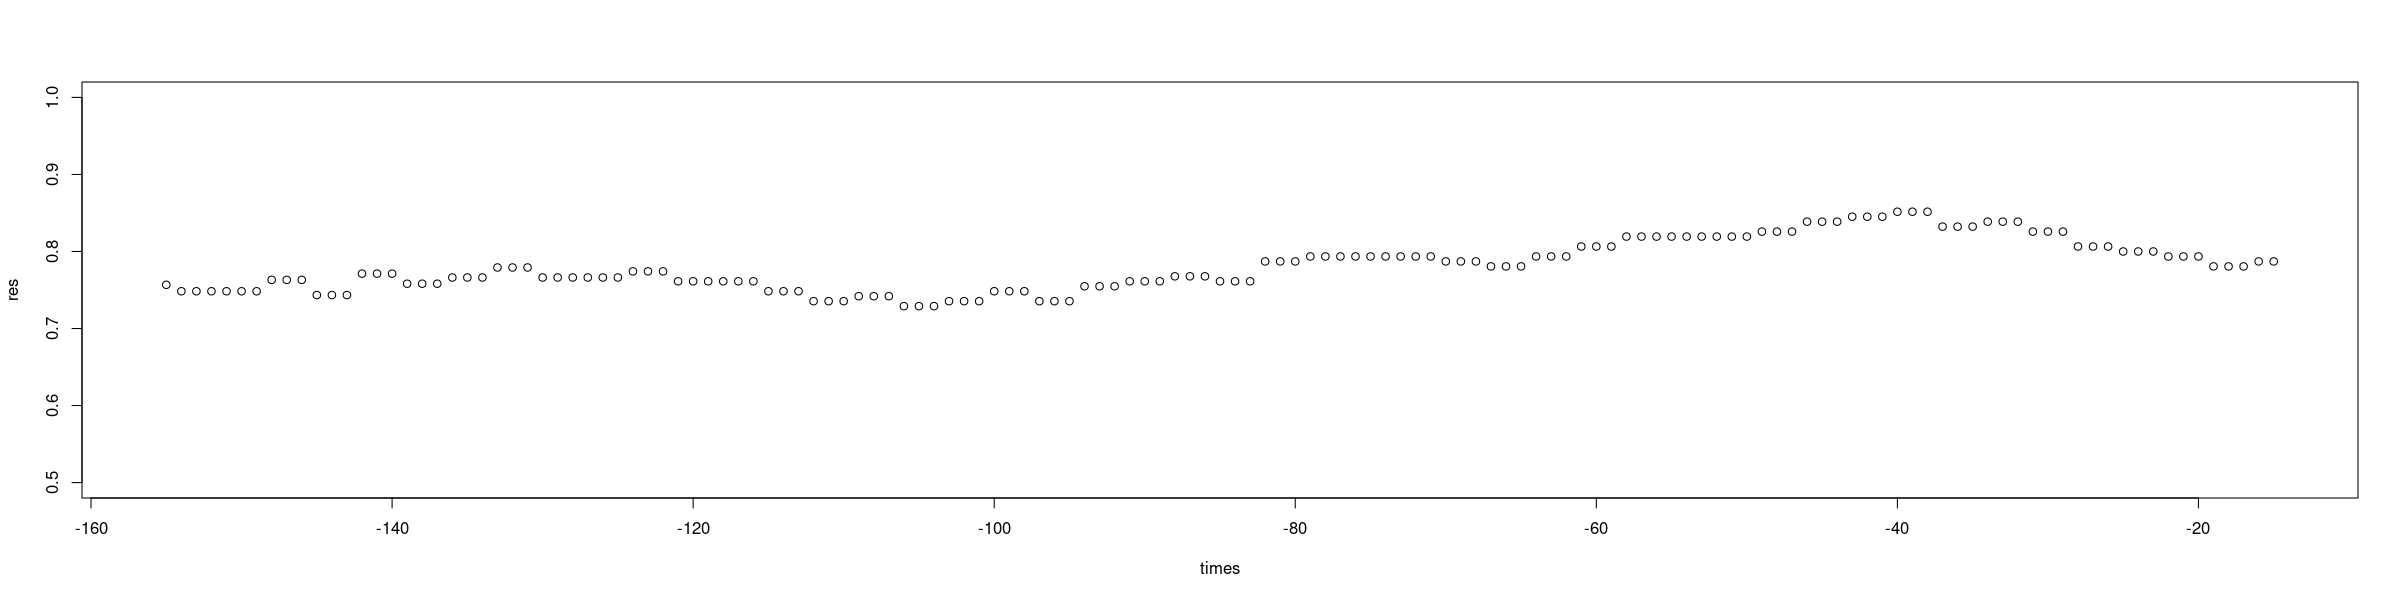

In [76]:
#png("classif_score.png")
plot(times, res, ylim=c(0.5,1))
#dev.off()

In [77]:
df = data.frame( cbind(times, res) )
names(df) = c("Time", "StiffScore")
write.table( df, paste(resf, "/OoStiffScore_", scoreName, "_alltimes.txt", sep=""), col.names=T, row.names=F)

## Calculate the sore at one time point

In [78]:
source("ooScaling.R")

dt = 10     ## Half size of temporal window average
time = -40 ## At which time point to calculate the KO score

tmin = time-dt
tmax = time+dt

## scale from Ana dataset only
scaling_data = scaleTimeToGP( rfdatas, tmin, tmax, 0, NULL, 1)
scaled_datas = as.data.frame(scaling_data[[1]])
scales = scaling_data[[2]]
head(scaled_datas)
saveRDS( scales, file=paste(resf, "/scaling_t", tmin, "_dt_", dt, ".Rds", sep="") )

## scale all dataset with the calculated scaling
#scale = readRDS(file=paste(resmouse, "/scaling_t", tmin, "_dt_", dt, ".Rds", sep="") )
scaling_data = scaleTimeToGP( rdatas, tmin, tmax, 1, scales, 1)       
scaled_datas = as.data.frame(scaling_data[[1]])

,Time,OoArea,OoMajorAxisLength,OoMinorAxisLength,OoEllAspectRatio,OoFeretDiam,OoPerimeter,OoCircularity,OoRoundness,OoConvexity,⋯,OoParticleDistanceCoefVar,OoParticleNumber,OoParticleAverageSize,OoDiameter,TimeToGP,OoNormedAR,OoNormedPIVDirCenter,OoNormedPIVAngleEdge,OoNormedFluctuationSpatialPower,OoNormedFluctuationLocalMean
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,171,1.15999274,0.53136605,1.4519863,-0.94030668,0.60050508,1.10764044,0.5761596,1.01327634,0.6740106,⋯,0.3815704,1.3382788,0.3903785,1.10764044,-39,0.28537524,-0.9699634,-0.43036197,0.9228862,1.8795946
2,159,0.31533329,-0.11308711,0.6566296,-0.76887679,-0.18559057,0.27075667,0.4769201,0.81358939,0.2962755,⋯,0.1765494,1.1309147,2.3883022,0.27075667,-39,0.30397711,-0.3137782,1.01065588,0.5940813,2.0911308
3,177,1.09233788,1.55661718,0.4085363,0.97487580,1.66493855,1.13489948,-0.5523107,-1.05165368,0.1981625,⋯,-0.6191531,0.1632156,1.5080432,1.13489948,-39,0.40446959,-0.9684219,0.82599134,0.3727472,1.6793524
4,177,-1.34516169,0.07956591,-2.3019428,2.63983586,-0.04697101,-1.27867274,-2.0318028,-2.59142627,0.1294834,⋯,0.5378278,-0.6892812,0.2365331,-1.27867274,-39,0.09722468,-1.0327995,0.19975346,0.2574031,-0.3735183
5,195,-1.04417879,-1.40926212,-0.4726851,-0.86119342,-1.33052952,-1.10091915,-0.1141834,0.92210094,-1.7493809,⋯,-1.8544406,-1.2422522,-1.2574856,-1.10091915,-39,-1.85108412,1.1581013,-0.06910881,-1.3852017,-1.0245410
6,183,0.09906867,0.08026170,0.1137800,-0.06626546,0.20822808,0.07672098,0.1462662,0.02710531,-0.3316478,⋯,1.1388314,-0.0902294,1.2567009,0.07672098,-39,-0.12452881,1.0725891,-0.78757574,-0.1295278,1.7375725


### Calculate the score and show histrogram of the score

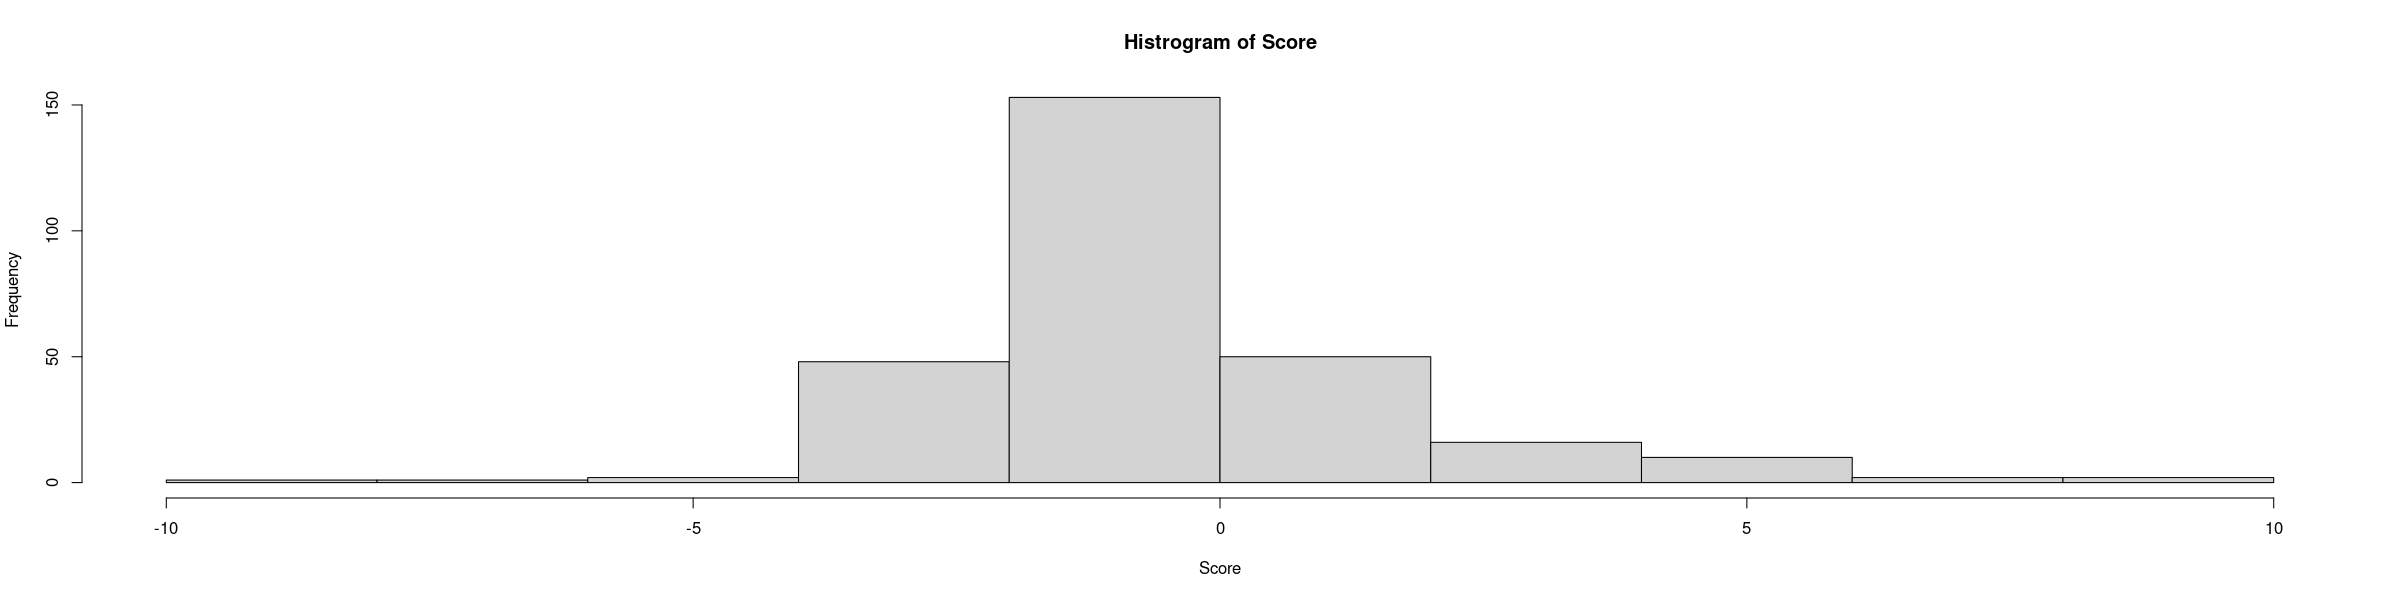

In [80]:
# Test score mix features
ooscores =  scaled_datas$OoFluctuationFromLocalMean+ scaled_datas$OoPIVAngleEdge - scaled_datas$OoNormedFluctuationSpatialPower - scaled_datas$OoNormedAR + scaled_datas$OoPIVStrengthDirectionCenter
ooscores =  scaled_datas$OoFluctuationFromLocalMean - scaled_datas$OoNormedFluctuationSpatialPower - scaled_datas$OoNormedAR 

#ooscores =  scaled_datas$OoFluctuationFromLocalMean - scaled_datas$OoNormedFluctuationSpatialPower - scaled_datas$OoEllAspectRatio
#ooscores =  scaled_datas$OoFluctuationFromLocalMean - scaled_datas$OoNormedFluctuationSpatialPower - scaled_datas$OoEllAspectRatio 
#ooscores =  scaled_datas$OoFluctuationFromLocalMean - scaled_datas$OoNormedAR 
scoreName = "Score"           ## to save the files or display titles


#ooscores =  scaled_datas$OoPIVStrengthDirectionCenter - scaled_datas$OoNormedFluctuationSpatialPower - scaled_datas$OoNormedAR
#ooscores =  scaled_datas$OoPIVStrengthDirectionCenter + scaled_datas$OoFluctuationFromLocalMean - scaled_datas$OoNormedAR
#scoreName = "ScorePIV"           ## to save the files or display titles

hist(ooscores, xlab=scoreName, main=paste("Histrogram of ", scoreName, sep=""))

In [81]:
anaset = scaled_datas$Type<=2
print( (sum(scaled_datas$Type[anaset&ooscores>0]==2)+sum(scaled_datas$Type[anaset&ooscores<=0]==1)) / sum(scaled_datas$Type<=2) )
print( sum(scaled_datas$Type[!anaset&ooscores<=0]>=3) / sum(scaled_datas$Type>2) )

[1] 0.8516129
[1] 0.8846154


### Sort oocytes by their score and show the ordered list

In [82]:
sort_scores = order(ooscores)
ordered_nums = scaled_datas$Num[sort_scores]
ordered_scores = ooscores[sort_scores]
sorted_oocytes = c()
for (i in 1:length(ordered_nums))
{
    num = ordered_nums[i]
    sorted_oocytes = rbind(sorted_oocytes, cbind(whos[which(whos$Num==num),], ordered_scores[i]))
}

sorted_oocytes

,Movie,Folder,Num,ordered_scores[i]
,<chr>,<chr>,<int>,<dbl>
164,movo_481,Miv,164,-8.693498
110,NI pos4_oocytor,Ana/n_12.12.23,110,-6.152897
37,NI pos2 L oocytor,Ana/_23.03.23,37,-5.567551
233,movo_296,Mivbis,233,-5.484119
578,movo_249,Mivter,578,-3.924975
184,movo_502,Miv,184,-3.900274
435,movo_89,Mivter,435,-3.856035
228,movo_289,Mivbis,228,-3.812082
39,NI pos3 R oocytor,Ana/_23.03.23,39,-3.804447


In [83]:
## save the list of oocytes with their score
write.table( sorted_oocytes, paste(resf, "/OoScore_", scoreName, "_t", time, ".txt", sep=""), col.names=T, row.names=F)

In [84]:
## add the score to the table data
rdatas$Score = rep(NA, length(rdatas$Num))
rdatas$Speed = rep(NA, length(rdatas$Num))
for (num in unique(rdatas$Num))
{
    keep = rdatas$Num == num
    rdatas$Score[keep] = ooscores[scaled_datas$Num==num]
    rdatas$Speed[keep] = min(rdatas$TimeToGP[keep])
}

In [97]:
## Plot feature against feature and color the points by score
plotFeatureFeatureScore = function(data, feat, ofeat, tmin, tmax, color_feature, x, y, yb)
{
	data = data[data$TimeToGP>=tmin&data$TimeToGP<=tmax,]
    mcdata = aggregate( data, list(data$Num), mean )
	ct = (tmax+tmin)/2
	mcdata$Time = ct
	mcdata = as.data.frame(mcdata)
	mcdata$Type = as.factor(mcdata$Type)

	p = ggplot(mcdata, aes(x=get(feat), y=get(ofeat), group=Num, colour=get(color_feature)) )	
	p = p + geom_point(size=8, alpha=1)
	p = p +theme(legend.position="none") 

	p = p + theme_plots()
    p = p + xlab(feat)
    p = p + ylab(ofeat)
    
    p = p + scale_colour_manual(values=myCol )
	p = p + scale_fill_manual(values=myCol )
    #p = p + scale_color_gradient(low="green", high="red")
    #p = p + scale_fill_gradient(low="green", high="red")
		#p = p + ylim(61,84)
    indfeat = which(names(mcdata)==feat)
    oindfeat = which(names(mcdata)==ofeat)
    
    print(cor.test(mcdata[,indfeat], mcdata[,oindfeat]))
    cor = cor.test(mcdata[,indfeat], mcdata[,oindfeat])
    p = p + geom_text(x=x, y=y, label=paste("Pearson correlation: p-val: ", format(cor$p.value, digits=3), sep=""), color="black", size=11)
	p = p + geom_text(x=x, y=yb, label=paste("Coef: ", format(cor$estimate[1], digits=3), sep=""), color="black", size=11)
	
    return(p)
}

In [98]:
names(rdatas)

[1] "Time"                            "OoArea"                         
 [3] "OoMajorAxisLength"               "OoMinorAxisLength"              
 [5] "OoEllAspectRatio"                "OoFeretDiam"                    
 [7] "OoPerimeter"                     "OoCircularity"                  
 [9] "OoRoundness"                     "OoConvexity"                    
[11] "OoCurvatureMean"                 "OoCurvatureStd"                 
[13] "OoCurvatureCoefVar"              "OoCurvatureMax"                 
[15] "OoCurvatureMin"                  "OoCurvatureFlatProp"            
[17] "OoCurvatureBendingEnergy"        "OoCurvatureNormalisedMean"      
[19] "OoCurvatureNormalisedMax"        "OoCurvatureNormalisedMin"       
[21] "OoCurvatureNormalisedStd"        "OoKurtosis"                     
[23] "OoNormMean"                      "OoNormStd"                      
[25] "OoNormCoefVar"                   "Type"                           
[27] "Num"                             "PerivArea"                      
[29] "PerivOoAreaRatio"                "PerivThicknessMean"             
[31] "PerivThicknessMin"               "PerivThicknessMax"              
[33] "PerivThicknessStd"               "PerivThicknessCoefVar"          
[35] "OoGLCMAngular2Moment"            "OoGLCMEntropy"                  
[37] "OoGLCMInverseDiffMoment"         "OoGLCMClusterTendency"          
[39] "OoGLCMClusterShade"              "OoGLCMCorrelation"              
[41] "OoGLCMContrast"                  "OoGLCMHomogeneity"              
[43] "OoGLCMVariance"                  "OoMoranIndexK5"                 
[45] "OoMoranIndexK20"                 "ZPGLCMAngular2Moment"           
[47] "ZPGLCMEntropy"                   "ZPGLCMInverseDiffMoment"        
[49] "ZPGLCMClusterTendency"           "ZPGLCMClusterShade"             
[51] "ZPGLCMCorrelation"               "ZPGLCMContrast"                 
[53] "ZPGLCMHomogeneity"               "ZPGLCMVariance"                 
[55] "OoFluctuationMean"               "OoFluctuationStd"               
[57] "OoFluctuationPropMoving"         "OoFluctuationPropGrowing"       
[59] "OoFluctuationSpatialMode"        "OoFluctuationSpatialPower"      
[61] "OoFluctuationSpatialCorrLength"  "OoFluctuationFromLocalMean"     
[63] "OoFluctuationFromLocalStd"       "OoRadiusMean"                   
[65] "OoRadiusStd"                     "OoRadiusDiffMean"               
[67] "OoRadiusDiffStd"                 "OoPIVMean"                      
[69] "OoPIVStd"                        "OoPIVCoefVar"                   
[71] "OoPIVMeanCenter"                 "OoPIVMeanEdge"                  
[73] "OoPIVAngleCenter"                "OoPIVAngleEdge"                 
[75] "OoPIVAverageDirection"           "OoPIVStrengthDirection"         
[77] "OoPIVAverageDirectionCenter"     "OoPIVAverageDirectionEdge"      
[79] "OoPIVStrengthDirectionCenter"    "OoPIVStrengthDirectionEdge"     
[81] "OoParticleDistanceMean"          "OoParticleDistanceStd"          
[83] "OoParticleDistanceCoefVar"       "OoParticleNumber"               
[85] "OoParticleAverageSize"           "OoDiameter"                     
[87] "TimeToGP"                        "OoNormedAR"                     
[89] "OoNormedPIVDirCenter"            "OoNormedPIVAngleEdge"           
[91] "OoNormedFluctuationSpatialPower" "OoNormedFluctuationLocalMean"   
[93] "Score"                           "Speed"


	Pearson's product-moment correlation

data:  mcdata[, indfeat] and mcdata[, oindfeat]
t = 6.0035, df = 283, p-value = 5.907e-09
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 0.2288572 0.4352953
sample estimates:
      cor 
0.3361071 



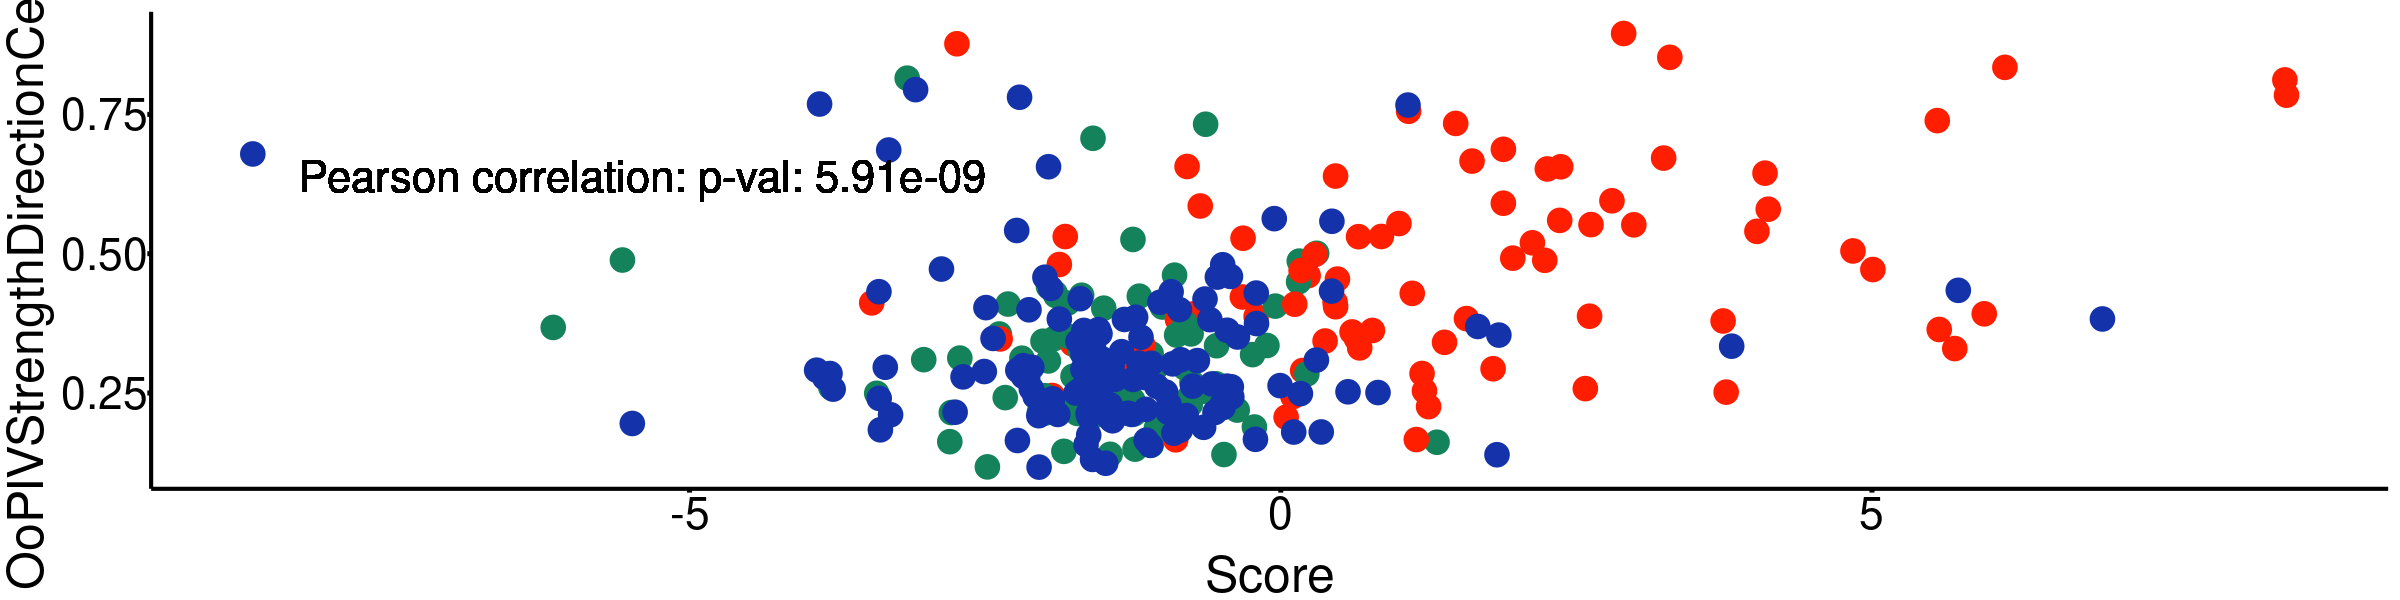

In [114]:
feature = "Score" # "Score"   ## feature to plot
feature_comp = "OoPIVStrengthDirectionCenter"
#feature_comp = "Speed"
#feature_comp = "OoPIVAngleEdge"
#feature_comp = "OoArea"
color_feature = "Type"   ## which feature to use for coloring (Type, Score)

dt = 10                        ## half-time interval on which datas are averaged
time = -40      ## time to plot (central time). Data are averaged from central_time-dt to central_time+dt

tmin = time-dt
tmax = time+dt
p = plotFeatureFeatureScore(rdatas, feature, feature_comp, tmin, tmax, color_feature, -5.4, 0.64, 1.25)
p

In [115]:
## save the plot
ggsave(plot=p, paste(resf, "/", "Oo", scoreName, "_", feature_comp, "_t", time, ".svg", sep=""), width=12, height=8)

In [96]:
rdatas$Num[rdatas$Score < -5.5]

[1]  37  37  37  37  37  37  37  37  37  37  37  37  37  37  37  37  37  37
 [19]  37  37  37  37  37  37  37  37  37  37  37  37  37  37  37  37  37  37
 [37]  37  37  37  37 110 110 110 110 110 110 110 110 110 110 110 110 110 110
 [55] 110 110 110 110 110 110 110 110 110 110 110 110 110 110 110 110 110 110
 [73] 110 110 110 110 110 110 110 110 110 110 110 110 110 110 164 164 164 164
 [91] 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164
[109] 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164
[127] 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164
[145] 164 164 164 164 164 164 164 164 164 164 164

In [71]:
rdatas$Num[rdatas$Score < -5]

[1]  37  37  37  37  37  37  37  37  37  37  37  37  37  37  37  37  37  37
 [19]  37  37  37  37  37  37  37  37  37  37  37  37  37  37  37  37  37  37
 [37]  37  37  37  37 110 110 110 110 110 110 110 110 110 110 110 110 110 110
 [55] 110 110 110 110 110 110 110 110 110 110 110 110 110 110 110 110 110 110
 [73] 110 110 110 110 110 110 110 110 110 110 110 110 110 110 163 163 163 163
 [91] 163 163 163 163 163 163 163 163 163 163 163 163 163 163 163 163 163 163
[109] 163 163 163 163 163 163 163 163 163 163 163 163 163 163 163 163 163 163
[127] 163 163 163 163 163 163 163 163 163 163 163 163 163 163 163 163 163 163
[145] 163 163 163 163 163 163 163 163 163 163 164 164 164 164 164 164 164 164
[163] 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164
[181] 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164
[199] 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164 164
[217] 164 164 164 164 164 164 164 184 184 184 184 184 184 184 184 184 184 184
[235] 184 184 184 184 184 184 184 184 184 184 184 184 184 184 184 184 184 184
[253] 184 184 184 184 184 184 184 184 184 184 184 184 184 184 184 184 184 184
[271] 184 184 184 184 184 184 184 184 184 184 184 184 184 184 184 184 184 184
[289] 184 184 184 184 184 184 184 184 184 184 184 184 199 199 199 199 199 199
[307] 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199
[325] 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199
[343] 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199 199
[361] 199 199 199 199 199 199

In [312]:
names(scaled_datas)
score

[1] "Time"                            "OoArea"                         
 [3] "OoMajorAxisLength"               "OoMinorAxisLength"              
 [5] "OoEllAspectRatio"                "OoFeretDiam"                    
 [7] "OoPerimeter"                     "OoCircularity"                  
 [9] "OoRoundness"                     "OoConvexity"                    
[11] "OoCurvatureMean"                 "OoCurvatureStd"                 
[13] "OoCurvatureCoefVar"              "OoCurvatureMax"                 
[15] "OoCurvatureMin"                  "OoCurvatureFlatProp"            
[17] "OoCurvatureBendingEnergy"        "OoCurvatureNormalisedMean"      
[19] "OoCurvatureNormalisedMax"        "OoCurvatureNormalisedMin"       
[21] "OoCurvatureNormalisedStd"        "OoKurtosis"                     
[23] "OoNormMean"                      "OoNormStd"                      
[25] "OoNormCoefVar"                   "Type"                           
[27] "Num"                             "PerivArea"                      
[29] "PerivOoAreaRatio"                "PerivThicknessMean"             
[31] "PerivThicknessMin"               "PerivThicknessMax"              
[33] "PerivThicknessStd"               "PerivThicknessCoefVar"          
[35] "OoGLCMAngular2Moment"            "OoGLCMEntropy"                  
[37] "OoGLCMInverseDiffMoment"         "OoGLCMClusterTendency"          
[39] "OoGLCMClusterShade"              "OoGLCMCorrelation"              
[41] "OoGLCMContrast"                  "OoGLCMHomogeneity"              
[43] "OoGLCMVariance"                  "OoMoranIndexK5"                 
[45] "OoMoranIndexK20"                 "ZPGLCMAngular2Moment"           
[47] "ZPGLCMEntropy"                   "ZPGLCMInverseDiffMoment"        
[49] "ZPGLCMClusterTendency"           "ZPGLCMClusterShade"             
[51] "ZPGLCMCorrelation"               "ZPGLCMContrast"                 
[53] "ZPGLCMHomogeneity"               "ZPGLCMVariance"                 
[55] "OoFluctuationMean"               "OoFluctuationStd"               
[57] "OoFluctuationPropMoving"         "OoFluctuationPropGrowing"       
[59] "OoFluctuationSpatialMode"        "OoFluctuationSpatialPower"      
[61] "OoFluctuationSpatialCorrLength"  "OoFluctuationFromLocalMean"     
[63] "OoFluctuationFromLocalStd"       "OoRadiusMean"                   
[65] "OoRadiusStd"                     "OoRadiusDiffMean"               
[67] "OoRadiusDiffStd"                 "OoPIVMean"                      
[69] "OoPIVStd"                        "OoPIVCoefVar"                   
[71] "OoPIVMeanCenter"                 "OoPIVMeanEdge"                  
[73] "OoPIVAngleCenter"                "OoPIVAngleEdge"                 
[75] "OoPIVAverageDirection"           "OoPIVStrengthDirection"         
[77] "OoPIVAverageDirectionCenter"     "OoPIVAverageDirectionEdge"      
[79] "OoPIVStrengthDirectionCenter"    "OoPIVStrengthDirectionEdge"     
[81] "OoParticleDistanceMean"          "OoParticleDistanceStd"          
[83] "OoParticleDistanceCoefVar"       "OoParticleNumber"               
[85] "OoParticleAverageSize"           "OoDiameter"                     
[87] "TimeToGP"                        "OoNormedAR"                     
[89] "OoNormedPIVDirCenter"            "OoNormedPIVAngleEdge"           
[91] "OoNormedFluctuationSpatialPower" "OoNormedFluctuationLocalMean"

ERROR: Error: objet 'score' introuvable


In [96]:
whos[whos$Num==223,]

,Movie,Folder,Num
,<chr>,<chr>,<int>
223,movo_280,Mivbis,223


In [36]:
print(unique(whos$Folder))
whos[whos$Folder=="Miv" & whos$Movie=="movo_480",]

 [1] "Ana/_13.04.23"  "Ana/_17.04.23"  "Ana/_22.03.23"  "Ana/_23.03.23" 
 [5] "Ana/02.02.2023" "Ana/08.02.2023" "Ana/09.01.2023" "Ana/16.01.2023"
 [9] "Ana/n_12.12.23" "Ana/n_16.01.24" "Ana/n_19.12.23" "Miv"           
[13] "Mivbis"        


,Movie,Folder,Num
,<chr>,<chr>,<int>
163,movo_480,Miv,163


In [38]:
oocheck = scaled_datas[scaled_datas$Num==261,]

print(oocheck$OoFluctuationFromLocalMean)  ## pos
print(oocheck$OoPIVAngleEdge) ## pos 
print(oocheck$OoNormedFluctuationSpatialPower) ## neg
print(oocheck$OoNormedAR)  ## neg
print(oocheck$OoPIVStrengthDirectionCenter)  ## pos

[1] -0.680327
[1] -2.353185
[1] 2.134303
[1] 0.8936705
[1] 0.02764424


In [31]:
unique(rdatas$Score[rdatas$Num==261])

[1] -6.033841